# Expérience — Nettoyage, variables calculées et ensemble de cinq modèles

L'[expérience 03](03_xgboost.ipynb) a montré qu'un modèle XGBoost bien réglé fait mieux que le LLM avec RAG filtré. Ses pistes (section 9) proposaient un encodage ordinal des qualités, d'autres variables combinées et une combinaison de méthodes. Ce notebook applique la recette la plus courante pour ce concours :

1. **Nettoyer les données** : retirer les deux ventes atypiques, traiter `MSSubClass`, `MoSold` et `YrSold` comme des catégories, réduire l'asymétrie des variables numériques.
2. **Créer des variables** : surfaces et salles de bain totales, âges, indicateurs de présence, qualités encodées dans l'ordre.
3. **Comparer cinq modèles** de natures différentes sur les mêmes données préparées.
4. **Les combiner** en un ensemble.

La partition (80 % / 20 %, graine 42), les 292 maisons de validation et la métrique (RMSE des logarithmes) sont **les mêmes** que dans les expériences 01 à 03.

### Résultats précédents (maisons de validation)

| Méthode | RMSE des logarithmes |
|---|---|
| LLM + RAG filtré v2 (exp. 02) | 0,133 |
| XGBoost, modèle retenu (exp. 03) | 0,130 |
| XGBoost, configuration manuelle (exp. 03) | 0,125 |

### Les cinq modèles

| Modèle | Famille | Pourquoi |
|---|---|---|
| Lasso (+ `RobustScaler`) | Linéaire, pénalité L1 | Après passage au logarithme, le prix est presque linéaire dans les surfaces et la qualité; la pénalité L1 met à zéro les colonnes inutiles. |
| ElasticNet (+ `RobustScaler`) | Linéaire, pénalités L1 et L2 | Comme le Lasso, mais partage le poids entre colonnes corrélées au lieu d'en choisir une. |
| Kernel Ridge (noyau polynomial) | Linéaire dans un espace élargi | Le noyau de degré 2 ajoute implicitement les carrés et les produits de variables : capte certaines non-linéarités. |
| Gradient Boosting (perte de Huber) | Arbres | La perte de Huber est quadratique pour les petites erreurs et linéaire pour les grandes : les prix extrêmes pèsent moins. |
| XGBoost | Arbres | Capte les seuils et les interactions; référence de l'expérience 03. |

Les modèles linéaires et les arbres font des erreurs de nature différente. C'est cette diversité qui peut rendre l'ensemble meilleur que chacun de ses membres.

## 1. Configuration

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import ElasticNetCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler
from xgboost import XGBRegressor

# Repérer la racine depuis le dossier courant ou l'un de ses parents.
current = Path.cwd().resolve()
root = next(
    (path for path in (current, *current.parents) if (path / "pyproject.toml").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt MAP6014.")
data_dir = root / "data"

# Partition (identique aux expériences 01 à 03)
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

# Validation croisée sur l'entraînement
N_FOLDS = 5

# Prétraitement
SKEW_THRESHOLD = 0.75     # log1p des variables numériques plus asymétriques que ce seuil
MIN_CATEGORY_COUNT = 5    # modalités plus rares regroupées par l'encodage one-hot

# Section 5.3 : comparer les choix de l'expérience à ceux de l'étape 4 (environ 5 minutes)
RUN_PREPROCESSING_COMPARISON = True

# Soumission Kaggle (fichier ignoré par Git)
MAKE_SUBMISSION = True
submission_path = root / "submissions" / "04_ensemble.csv"

# LassoCV et ElasticNetCV testent de très faibles pénalités, qui convergent lentement;
# ces combinaisons ne sont jamais retenues. Leurs avertissements sont masqués.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
print(f"XGBoost {xgboost.__version__}")


def format_dollars(value):
    """Afficher un montant en dollars avec une espace comme séparateur de milliers."""
    return f"{value:,.0f} $".replace(",", " ")


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

XGBoost 3.4.1


## 2. Partition entraînement / validation

Même partition que les expériences précédentes. Tous les choix (modèles, poids de l'ensemble, modèle final) sont faits par **validation croisée sur l'entraînement**; la validation ne sert qu'une fois, à la fin.

In [2]:
read_options = {"na_values": ["NA"], "keep_default_na": False}
train_full = pd.read_csv(data_dir / "train.csv", **read_options)
test = pd.read_csv(data_dir / "test.csv", **read_options)
assert train_full.shape == (1460, 81) and test.shape == (1459, 80)

train_part, valid_part = train_test_split(
    train_full, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE
)
train_part = train_part.reset_index(drop=True)
valid_part = valid_part.reset_index(drop=True)
assert not set(train_part["Id"]) & set(valid_part["Id"])

# Cible : logarithme du prix, l'échelle de la métrique Kaggle.
y_train = np.log(train_part["SalePrice"])
y_valid = np.log(valid_part["SalePrice"])

display(pd.DataFrame({
    "Partition": ["Entraînement", "Validation", "test.csv (soumission)"],
    "Maisons": [len(train_part), len(valid_part), len(test)],
    "Prix médian": [format_dollars(train_part["SalePrice"].median()),
                    format_dollars(valid_part["SalePrice"].median()), "inconnu"],
}))

,Partition,Maisons,Prix médian
0,Entraînement,1168,165 000 $
1,Validation,292,154 150 $
2,test.csv (soumission),1459,inconnu


## 3. Nettoyage des données

### 3.1 Les deux ventes atypiques

Dean De Cock, l'auteur du jeu de données, recommande de retirer les maisons de plus de 4 000 pi² habitables : quelques-unes sont des ventes partielles vendues bien sous leur valeur. Dans `train.csv`, deux maisons (Id 524 et 1299) ont plus de 4 500 pi² et un prix inférieur à 185 000 \$, alors que la tendance prédit plus de 500 000 \$.

Ces deux ventes ont un grand **levier** pour un modèle linéaire : à elles seules, elles peuvent faire pivoter la pente de la surface. Nous les retirons **des données d'entraînement** de chaque modèle.

**Et de l'évaluation?** L'expérience 03 les gardait dans les plis d'évaluation, pour ne pas embellir le score. Avec des modèles linéaires, ce choix pose un problème : un bon modèle linéaire prédit environ 2 millions de dollars pour la maison 1299, vendue 160 000 \$, soit une erreur logarithmique d'environ 2,5. Ce **seul** carré d'erreur (≈ 6,3) pèse autant que ceux de 500 maisons ordinaires (≈ 0,012 chacun) : il gonfle fortement la RMSE de son pli et classerait les modèles selon leur façon de rater une vente qu'aucune variable disponible ne permet de prévoir. Nous considérons donc ces deux ventes comme **hors de la population à prédire**, comme le recommande l'auteur du jeu de données. Le critère de sélection est la RMSE sur les **ventes typiques** (toutes les maisons sauf ces deux); la RMSE sur toutes les ventes est affichée à côté pour transparence. La validation finale (section 6) ne contient aucune de ces ventes et n'est pas touchée par ce choix.

Ventes atypiques dans l'entraînement : [524, 1299]
Ventes atypiques dans la validation : []


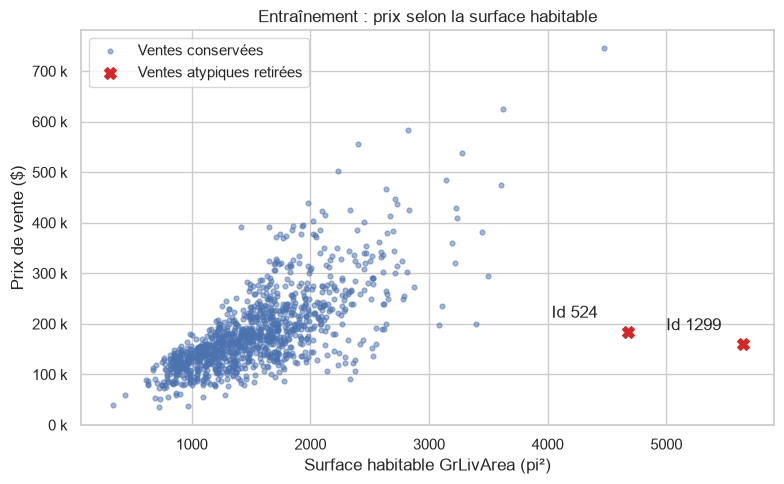

In [3]:
def atypical_mask(frame):
    return (frame["GrLivArea"].gt(4000) & frame["SalePrice"].lt(300_000)).to_numpy()


atypical = atypical_mask(train_part)
print(f"Ventes atypiques dans l'entraînement : {train_part.loc[atypical, 'Id'].tolist()}")
print(f"Ventes atypiques dans la validation : "
      f"{valid_part.loc[atypical_mask(valid_part), 'Id'].tolist()}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train_part.loc[~atypical, "GrLivArea"], train_part.loc[~atypical, "SalePrice"],
           s=12, alpha=0.5, label="Ventes conservées")
ax.scatter(train_part.loc[atypical, "GrLivArea"], train_part.loc[atypical, "SalePrice"],
           s=70, color="tab:red", marker="X", label="Ventes atypiques retirées")
for _, row in train_part.loc[atypical].iterrows():
    ax.annotate(f"Id {row['Id']}", (row["GrLivArea"], row["SalePrice"]),
                xytext=(-55, 10), textcoords="offset points")
ax.set(xlabel="Surface habitable GrLivArea (pi²)", ylabel="Prix de vente ($)",
       title="Entraînement : prix selon la surface habitable")
ax.yaxis.set_major_formatter(lambda value, _: f"{value / 1000:.0f} k")
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Corrections, variables calculées et encodage ordinal

La fonction `prepare_features` traite chaque maison **séparément**, sans rien apprendre des données; elle peut donc s'appliquer avant la validation croisée sans fuite d'information.

**Corrections** (reprises de l'expérience 03) :

- Pour 14 variables catégorielles, `NA` signifie l'**absence** de l'élément (pas de sous-sol, pas de piscine…) : remplacé par `"Aucun"`.
- Les surfaces et comptes de sous-sol et de garage absents valent **0**. Une année de garage absente (ou postérieure à la vente) est remplacée par l'année de construction.
- Trois codes mal orthographiés de `Exterior2nd` sont uniformisés avec `Exterior1st`.

**Faux numériques.** `MSSubClass` est un code de type de logement (20 = plain-pied récent, 60 = deux étages…) : la valeur 60 n'est pas « trois fois » la valeur 20. `MoSold` et `YrSold` n'ont pas d'effet linéaire attendu sur le prix (saison, crise de 2008). Ces trois variables deviennent des **catégories**, après avoir servi au calcul des âges.

**Variables calculées** :

| Variable | Définition |
|---|---|
| `TotalSF` | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` |
| `TotalBath` | `FullBath + 0,5 × HalfBath + BsmtFullBath + 0,5 × BsmtHalfBath` |
| `HouseAge` | `YrSold − YearBuilt` |
| `RemodAge` | `YrSold − YearRemodAdd` |
| `TotalPorchSF` | `OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch` |
| `HasPool`, `HasGarage`, `Has2ndFlr` | 1 si `PoolArea`, `GarageArea` ou `2ndFlrSF` est positif, sinon 0 |

**Encodage ordinal des qualités.** Dix variables utilisent la même échelle de qualité. Au lieu d'une colonne binaire par modalité, elles deviennent un **seul nombre** qui respecte l'ordre : `Ex` = 5, `Gd` = 4, `TA` = 3, `Fa` = 2, `Po` = 1, et `Aucun` = 0. Un modèle linéaire peut alors apprendre « un niveau de qualité de plus vaut x % de prix », et un arbre peut séparer « bon ou mieux » de « moyen ou moins » en une seule division.

In [4]:
ABSENCE_COLUMNS = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]
ABSENCE_NUMERIC = [
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
    "GarageCars", "GarageArea", "MasVnrArea",
]
EXTERIOR2_FIXES = {"Wd Shng": "WdShing", "CmentBd": "CemntBd", "Brk Cmn": "BrkComm"}
QUALITY_SCALE = {"Aucun": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUALITY_COLUMNS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]
FAKE_NUMERIC = ["MSSubClass", "MoSold", "YrSold"]
PORCH_COLUMNS = ["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]


def prepare_features(frame, dates_as_category=True):
    """Corrections, variables calculées et encodages, maison par maison (aucun apprentissage).

    dates_as_category=False garde MoSold et YrSold numériques (choix de l'étape 4, section 5.3).
    """
    X = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()

    # Corrections
    X[ABSENCE_COLUMNS] = X[ABSENCE_COLUMNS].fillna("Aucun")
    X[ABSENCE_NUMERIC] = X[ABSENCE_NUMERIC].fillna(0)
    X.loc[X["GarageYrBlt"].gt(X["YrSold"]), "GarageYrBlt"] = np.nan
    X["GarageYrBlt"] = X["GarageYrBlt"].fillna(X["YearBuilt"])
    X["Exterior2nd"] = X["Exterior2nd"].replace(EXTERIOR2_FIXES)

    # Variables calculées
    X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
    X["TotalBath"] = (X["FullBath"] + 0.5 * X["HalfBath"]
                      + X["BsmtFullBath"] + 0.5 * X["BsmtHalfBath"])
    X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
    X["RemodAge"] = X["YrSold"] - X["YearRemodAdd"]
    X["TotalPorchSF"] = X[PORCH_COLUMNS].sum(axis=1)
    X["HasPool"] = X["PoolArea"].gt(0).astype(int)
    X["HasGarage"] = X["GarageArea"].gt(0).astype(int)
    X["Has2ndFlr"] = X["2ndFlrSF"].gt(0).astype(int)

    # Qualités : échelle ordinale (une valeur absente reste NaN et sera imputée)
    unknown = set(X[QUALITY_COLUMNS].stack().dropna().unique()) - set(QUALITY_SCALE)
    assert not unknown, f"Modalités de qualité inattendues : {unknown}"
    X[QUALITY_COLUMNS] = X[QUALITY_COLUMNS].apply(lambda column: column.map(QUALITY_SCALE))

    # Faux numériques : codes et dates traités comme des catégories
    fake_numeric = FAKE_NUMERIC if dates_as_category else ["MSSubClass"]
    X[fake_numeric] = X[fake_numeric].astype(str)
    return X


X_train = prepare_features(train_part)
X_valid = prepare_features(valid_part)
X_test = prepare_features(test)

categorical_columns = [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_columns = [c for c in X_train.columns if c not in categorical_columns]
print(f"{len(categorical_columns)} variables catégorielles, {len(numeric_columns)} numériques "
      f"(dont 8 calculées et {len(QUALITY_COLUMNS)} qualités ordinales).")
missing = pd.concat([X_train, X_test]).isna().sum().loc[lambda s: s > 0]
print("Valeurs encore absentes (entraînement + test), imputées dans le pipeline :")
display(missing.rename("Maisons").to_frame().T)
display(X_train[["TotalSF", "TotalBath", "HouseAge", "RemodAge", "TotalPorchSF",
                 "HasPool", "HasGarage", "Has2ndFlr", "KitchenQual", "MSSubClass"]].head())

36 variables catégorielles, 51 numériques (dont 8 calculées et 10 qualités ordinales).
Valeurs encore absentes (entraînement + test), imputées dans le pipeline :


,MSZoning,LotFrontage,Utilities,Exterior1st,Exterior2nd,MasVnrType,Electrical,KitchenQual,Functional,SaleType
Maisons,4,444,2,1,1,22,1,1,2,1


,TotalSF,TotalBath,HouseAge,RemodAge,TotalPorchSF,HasPool,HasGarage,Has2ndFlr,KitchenQual,MSSubClass
0,2628,2.0,53,53,0,0,1,0,3,20
1,2370,2.5,16,15,40,0,1,1,3,60
2,1592,1.0,98,58,164,0,0,0,3,30
3,2499,2.5,70,57,264,0,1,1,4,50
4,2717,2.0,86,60,242,0,1,1,4,50


Les valeurs encore absentes sont de vraies valeurs **inconnues** (`LotFrontage` surtout, et quelques cases isolées de `test.csv`). Elles sont imputées dans le pipeline, avec des statistiques apprises sur les plis d'entraînement seulement : médiane pour les numériques, modalité la plus fréquente pour les catégorielles.

### 3.3 Asymétrie des variables numériques

Plusieurs surfaces ont une longue queue à droite : beaucoup de petites valeurs et quelques très grandes. Pour un modèle linéaire, ces quelques grandes valeurs pèsent trop dans l'ajustement, et l'effet d'un pied carré supplémentaire n'est pas le même pour une petite et une grande maison. Le transformateur `SkewedLog1p` ci-dessous :

1. calcule, **sur les données d'entraînement seulement**, le coefficient d'asymétrie (*skewness*) de chaque variable numérique;
2. applique `log1p(x) = log(1 + x)` aux variables positives dont l'asymétrie dépasse 0,75. Le `+1` garde les zéros (pas de sous-sol, pas de piscine) à zéro.

Nous utilisons `log1p` plutôt que Box-Cox : la transformation est fixe, plus simple à interpréter, et donne en pratique des résultats très proches sur ce jeu de données.

26 variables numériques sur 51 reçoivent log1p (asymétrie > 0.75).


,MiscVal,PoolQC,PoolArea,HasPool,LotArea,3SsnPorch,LowQualFinSF,KitchenAbvGr,BsmtFinSF2,ScreenPorch,BsmtHalfBath,EnclosedPorch
Asymétrie avant,22.03,15.68,14.38,13.84,11.94,9.82,9.19,4.44,4.21,4.09,4.00,3.16
Asymétrie après,5.00,14.55,13.86,13.84,-0.01,7.50,7.44,3.72,2.56,3.06,3.89,2.18


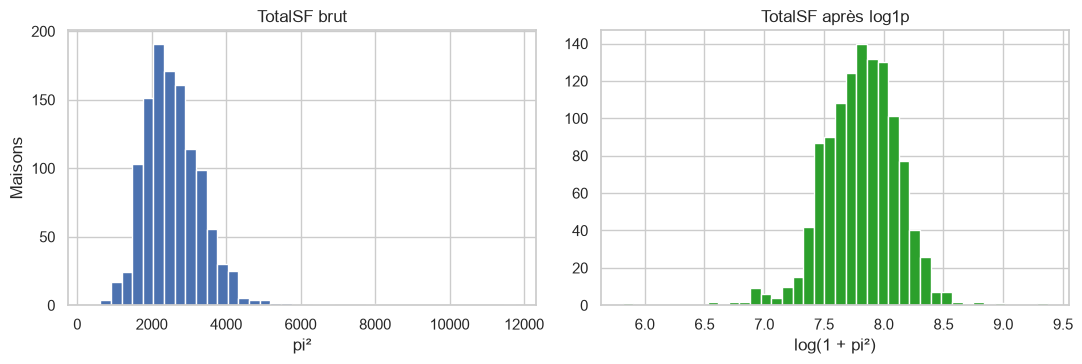

In [5]:
class SkewedLog1p(BaseEstimator, TransformerMixin):
    """Appliquer log1p aux colonnes positives dont l'asymétrie apprise dépasse un seuil.

    max_zero_share et exclude (positions de colonnes) reproduisent la règle de l'étape 4 :
    pas de log pour une colonne surtout nulle, ni pour une année, un score ou une échelle.
    """

    def __init__(self, threshold=0.75, max_zero_share=1.0, exclude=()):
        self.threshold = threshold
        self.max_zero_share = max_zero_share
        self.exclude = exclude

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)  # colonnes presque constantes
            self.skewness_ = skew(X, axis=0)
        eligible = ((self.skewness_ > self.threshold) & (X.min(axis=0) >= 0)
                    & ((X == 0).mean(axis=0) < self.max_zero_share))
        eligible[list(self.exclude)] = False
        self.columns_ = np.flatnonzero(eligible)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        X[:, self.columns_] = np.log1p(np.clip(X[:, self.columns_], 0, None))
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


imputed = SimpleImputer(strategy="median").fit_transform(X_train[numeric_columns])
skew_step = SkewedLog1p(SKEW_THRESHOLD).fit(imputed)
transformed = skew_step.transform(imputed)
skew_table = pd.DataFrame({
    "Asymétrie avant": skew_step.skewness_,
    "Asymétrie après": skew(transformed, axis=0),
}, index=numeric_columns).loc[lambda f: f.index.isin(np.array(numeric_columns)[skew_step.columns_])]
print(f"{len(skew_step.columns_)} variables numériques sur {len(numeric_columns)} "
      f"reçoivent log1p (asymétrie > {SKEW_THRESHOLD}).")
display(skew_table.sort_values("Asymétrie avant", ascending=False).head(12).round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
column = numeric_columns.index("TotalSF")
axes[0].hist(imputed[:, column], bins=40)
axes[0].set(title="TotalSF brut", xlabel="pi²", ylabel="Maisons")
axes[1].hist(transformed[:, column], bins=40, color="tab:green")
axes[1].set(title="TotalSF après log1p", xlabel="log(1 + pi²)")
plt.tight_layout()
plt.show()

### 3.4 Pipeline de prétraitement

Le pipeline complet est appris **dans chaque pli** de validation croisée, puis sur tout l'entraînement :

- **numériques** : imputation par la médiane → `SkewedLog1p` → `RobustScaler` (centre sur la médiane et divise par l'écart interquartile; une valeur extrême déplace peu ces statistiques, contrairement à la moyenne et à l'écart type);
- **catégorielles** : imputation par la modalité la plus fréquente → encodage *one-hot*, avec les modalités vues moins de 5 fois regroupées en « rares ».

Les cinq modèles reçoivent la **même matrice**. La mise à l'échelle est indispensable aux modèles linéaires pénalisés et au noyau polynomial (la pénalité et le noyau dépendent de l'échelle des colonnes); elle ne change rien pour les arbres, qui ne dépendent que de l'ordre des valeurs.

In [6]:
# Règle de log de l'étape 4 (src/preprocessing/steps/scaling.py), adaptée aux colonnes d'ici
STEP4_NO_LOG = ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold", "MoSold",
                "OverallQual", "OverallCond", "KitchenAbvGr", *QUALITY_COLUMNS]


def make_preprocessor(numeric=None, categorical=None, skew_rule="experience",
                      scaler="robust", min_count=MIN_CATEGORY_COUNT):
    """Prétraitement; les options autres que les valeurs par défaut servent à la section 5.3."""
    numeric = numeric_columns if numeric is None else numeric
    categorical = categorical_columns if categorical is None else categorical
    if skew_rule == "experience":
        skew_step = SkewedLog1p(SKEW_THRESHOLD)
    else:  # "etape4" : seuil 0,5, sans colonnes surtout nulles ni années, scores, échelles
        skew_step = SkewedLog1p(0.5, max_zero_share=0.5,
                                exclude=[i for i, c in enumerate(numeric) if c in STEP4_NO_LOG])
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("skew", skew_step),
        ("scale", RobustScaler() if scaler == "robust" else StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=min_count, sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", numeric_steps, numeric), ("cat", categorical_steps, categorical)],
        verbose_feature_names_out=False,
    )


preview = make_preprocessor().fit(X_train)
print(f"Matrice finale : {len(X_train)} maisons × {len(preview.get_feature_names_out())} "
      f"colonnes ({len(numeric_columns)} numériques, "
      f"{len(preview.get_feature_names_out()) - len(numeric_columns)} binaires).")

Matrice finale : 1168 maisons × 271 colonnes (51 numériques, 220 binaires).


## 4. Cinq modèles en validation croisée

### 4.1 Hyperparamètres

- **Lasso** et **ElasticNet** : `LassoCV` et `ElasticNetCV` choisissent la force de la pénalité (et, pour ElasticNet, la part L1/L2) par une validation croisée **interne** aux plis d'entraînement.
- **Kernel Ridge** : noyau polynomial de degré 2, `alpha` = 0,6, `coef0` = 2,5, valeurs usuelles pour ce concours.
- **Gradient Boosting** : 3 000 arbres de profondeur 4, taux d'apprentissage 0,05, perte de Huber, un sous-ensemble aléatoire de colonnes (`max_features="sqrt"`) à chaque division et au moins 15 maisons par feuille.
- **XGBoost** : la configuration manuelle de l'expérience 03 (2 000 arbres, profondeur 4, taux 0,02), qui y obtenait la meilleure erreur de validation.

### 4.2 Prédictions hors pli

La fonction `out_of_fold` entraîne chaque modèle sur 4 plis (sans les ventes atypiques) et prédit le 5ᵉ, cinq fois. Chaque maison de l'entraînement reçoit ainsi une prédiction faite **par un modèle qui ne l'a pas vue**. Ces prédictions hors pli servent à mesurer l'erreur de chaque modèle et, à la section 5, à construire l'ensemble.

In [7]:
MODELS = {
    "Lasso": LassoCV(alphas=np.logspace(-4.5, -1.5, 40), max_iter=50_000, n_jobs=-1),
    "ElasticNet": ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
                               alphas=np.logspace(-4.5, -1.5, 40), max_iter=50_000, n_jobs=-1),
    "Kernel Ridge": KernelRidge(alpha=0.6, kernel="polynomial", degree=2, coef0=2.5),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=3000, learning_rate=0.05, max_depth=4, max_features="sqrt",
        min_samples_leaf=15, min_samples_split=10, loss="huber", random_state=RANDOM_STATE,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=2000, learning_rate=0.02, max_depth=4, min_child_weight=2,
        subsample=0.7, colsample_bytree=0.5, reg_lambda=1.0,
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
    ),
}


def make_model(name, **prep_options):
    return Pipeline([("prep", make_preprocessor(**prep_options)), ("model", clone(MODELS[name]))])


cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
fold_id = np.empty(len(X_train), dtype=int)
for k, (_, eval_index) in enumerate(cv.split(X_train)):
    fold_id[eval_index] = k


def out_of_fold(name, drop_mask, X=None, **prep_options):
    """Prédictions hors pli; les maisons de drop_mask sont exclues de l'entraînement seulement."""
    X = X_train if X is None else X
    oof = np.empty(len(X))
    for fit_index, eval_index in cv.split(X):
        fit_index = fit_index[~drop_mask[fit_index]]
        model = make_model(name, **prep_options).fit(X.iloc[fit_index], y_train.iloc[fit_index])
        oof[eval_index] = model.predict(X.iloc[eval_index])
    return oof


typical = ~atypical
keep_all = np.ones(len(X_train), dtype=bool)


def fold_scores(prediction, mask=typical):
    """RMSE log de chaque pli, calculée sur les maisons de mask (par défaut : ventes typiques)."""
    return np.array([rmse(y_train[(fold_id == k) & mask], prediction[(fold_id == k) & mask])
                     for k in range(N_FOLDS)])


oof = {}
cv_rows = {}
for name in MODELS:
    start = time.perf_counter()
    oof[name] = out_of_fold(name, atypical)
    scores = fold_scores(oof[name])
    cv_rows[name] = {"RMSE log (moyenne des plis)": scores.mean(),
                     "Écart type entre plis": scores.std(),
                     "RMSE log, toutes les ventes": fold_scores(oof[name], keep_all).mean(),
                     "Durée (s)": time.perf_counter() - start}

cv_summary = pd.DataFrame(cv_rows).T
display(cv_summary.sort_values("RMSE log (moyenne des plis)")
        .style.format("{:.4f}", subset=["RMSE log (moyenne des plis)", "Écart type entre plis",
                                        "RMSE log, toutes les ventes"])
        .format("{:.1f}", subset=["Durée (s)"]))

print("Erreur log hors pli sur les deux ventes atypiques (prédiction − réel) :")
display(pd.DataFrame({name: oof[name][atypical] - y_train[atypical].to_numpy() for name in MODELS},
                     index=[f"Id {i}" for i in train_part.loc[atypical, "Id"]]).round(2))

,RMSE log (moyenne des plis),Écart type entre plis,"RMSE log, toutes les ventes",Durée (s)
Kernel Ridge,0.1104,0.0091,0.1351,0.5
ElasticNet,0.1112,0.0085,0.1339,16.0
Lasso,0.1117,0.0082,0.1347,3.0
Gradient Boosting,0.1122,0.0119,0.1220,42.3
XGBoost,0.1136,0.0131,0.1236,7.7


Erreur log hors pli sur les deux ventes atypiques (prédiction − réel) :


,Lasso,ElasticNet,Kernel Ridge,Gradient Boosting,XGBoost
Id 524,1.34,1.33,1.40,1.19,1.22
Id 1299,2.54,2.51,2.64,1.28,1.28


**Interprétation.** Sur les ventes typiques, les cinq modèles sont proches : de **0,1104** (Kernel Ridge) à 0,1136 (XGBoost), un écart de 0,003, inférieur à l'écart type entre plis (environ 0,01). Les trois modèles linéaires font légèrement mieux que les arbres : après le logarithme de la cible, `log1p` des surfaces et l'encodage ordinal des qualités, le prix est en bonne partie une somme d'effets. XGBoost, avec les hyperparamètres de la configuration manuelle de l'expérience 03, passe de 0,1195 à 0,1136 en ventes typiques; une partie de ce gain vient du nouveau prétraitement, et une partie du changement de critère (voir 4.3).

Le dernier tableau montre pourquoi les deux ventes atypiques sont exclues de l'évaluation : les modèles linéaires leur prédisent un prix 3,8 fois (524) et 12 à 14 fois (1299) trop élevé (erreurs log de 1,3 à 2,6). Les arbres ne peuvent pas extrapoler au-delà des prix vus à l'entraînement et se trompent « moins » (erreur log d'environ 1,2). Sur toutes les ventes, le classement s'inverse donc (0,122 pour Gradient Boosting contre 0,135 pour Kernel Ridge), mais uniquement à cause de deux maisons.

**Conséquence.** Aucun modèle ne domine nettement : les cinq sont conservés pour l'ensemble.

### 4.3 Effet du retrait des ventes atypiques

L'expérience 03 concluait que retirer les maisons 524 et 1299 de l'entraînement **nuisait** à XGBoost (0,1189 → 0,1230), mais elle les gardait dans l'évaluation. Nous croisons ici les deux choix, pour un modèle linéaire (Lasso) et pour XGBoost : entraîner avec ou sans ces ventes, et évaluer sur toutes les ventes ou sur les ventes typiques seulement.

In [8]:
outlier_rows = []
for name in ["Lasso", "XGBoost"]:
    trained_with = out_of_fold(name, ~keep_all)  # aucune maison exclue de l'entraînement
    for training, prediction in [("avec", trained_with), ("sans", oof[name])]:
        outlier_rows.append({
            "Modèle": name, "Entraînement": f"{training} les ventes atypiques",
            "Évaluation : toutes les ventes": fold_scores(prediction, keep_all).mean(),
            "Évaluation : ventes typiques": fold_scores(prediction).mean(),
        })
display(pd.DataFrame(outlier_rows).set_index(["Modèle", "Entraînement"]).round(4))

Évaluation : toutes les ventes  \
Modèle  Entraînement                                                
Lasso   avec les ventes atypiques                          0.1262   
        sans les ventes atypiques                          0.1347   
XGBoost avec les ventes atypiques                          0.1194   
        sans les ventes atypiques                          0.1236   

                                   Évaluation : ventes typiques  
Modèle  Entraînement                                             
Lasso   avec les ventes atypiques                        0.1139  
        sans les ventes atypiques                        0.1117  
XGBoost avec les ventes atypiques                        0.1155  
        sans les ventes atypiques                        0.1136

**Interprétation.** La conclusion dépend de l'évaluation. Si l'on évalue sur toutes les ventes, garder les deux maisons à l'entraînement semble meilleur (Lasso 0,1262 contre 0,1347; XGBoost 0,1194 contre 0,1236) : un modèle qui a vu ces ventes les prédit moins mal quand elles reviennent dans un pli d'évaluation. C'est la conclusion de l'expérience 03. Si l'on évalue sur les ventes typiques, les **retirer** améliore les deux modèles : Lasso de 0,1139 à **0,1117**, XGBoost de 0,1155 à **0,1136**. Le gain est plus grand pour le Lasso, comme attendu : deux points à fort levier faussent la pente de la surface pour toutes les grandes maisons.

**Conséquence.** Pour prédire des ventes ordinaires, retirer les deux ventes atypiques de l'entraînement aide les cinq modèles. Le désaccord avec l'expérience 03 vient du critère d'évaluation, pas du modèle.

## 5. Ensemble des cinq modèles

### 5.1 Les modèles se trompent-ils sur les mêmes maisons?

Un ensemble n'aide que si les erreurs de ses membres ne sont pas parfaitement corrélées : en moyenne, une surestimation de l'un compense alors une sous-estimation d'un autre.

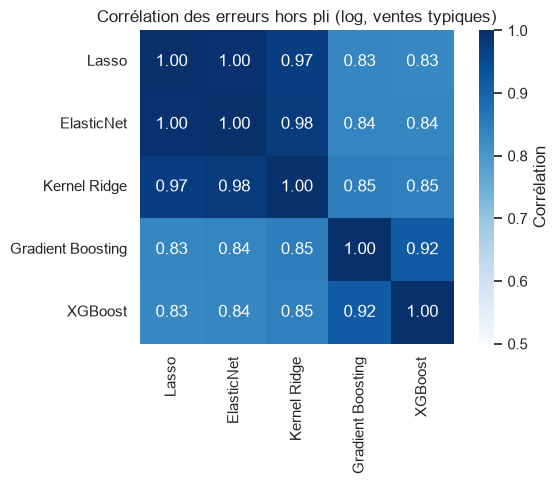

,Lasso,ElasticNet,Kernel Ridge,Gradient Boosting,XGBoost
Lasso,1.00,1.00,0.97,0.83,0.83
ElasticNet,1.00,1.00,0.98,0.84,0.84
Kernel Ridge,0.97,0.98,1.00,0.85,0.85
Gradient Boosting,0.83,0.84,0.85,1.00,0.92
XGBoost,0.83,0.84,0.85,0.92,1.00


In [9]:
oof_frame = pd.DataFrame(oof)
errors = oof_frame.sub(y_train.to_numpy(), axis=0)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(errors[typical].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0.5, vmax=1,
            square=True, cbar_kws={"label": "Corrélation"}, ax=ax)
ax.set_title("Corrélation des erreurs hors pli (log, ventes typiques)")
plt.tight_layout()
plt.show()
display(errors[typical].corr().round(2))

**Interprétation.** Les erreurs forment deux familles. Les trois modèles linéaires se trompent presque de la même façon (corrélation de 0,97 à 1,00 : Lasso et ElasticNet sont presque le même modèle). Les deux modèles d'arbres sont corrélés à 0,92 entre eux. **Entre les familles**, la corrélation tombe à 0,83–0,85 : un modèle linéaire et un modèle d'arbres se trompent souvent sur des maisons différentes. C'est là que l'ensemble peut gagner.

### 5.2 Deux façons de combiner

Les prédictions sont combinées **sur l'échelle logarithmique** (moyenne géométrique des prix), l'échelle de la métrique.

1. **Moyenne simple** : chaque modèle reçoit le poids 1/5. Aucun paramètre à apprendre.
2. **Moyenne pondérée** : les poids (positifs, de somme 1) minimisent la RMSE des prédictions hors pli.

Les poids de la moyenne pondérée sont appris sur les mêmes prédictions qui servent à l'évaluer : son score hors pli serait donc **optimiste**. Pour une estimation honnête, nous apprenons les poids sur 4 plis et évaluons sur le 5ᵉ, cinq fois. Les poids finaux sont ensuite appris sur les 5 plis.

,RMSE log (moyenne des plis),Écart type entre plis,"RMSE log, toutes les ventes"
Moyenne simple,0.1067,0.0106,0.1248
Moyenne pondérée,0.1068,0.0109,0.1231
Kernel Ridge,0.1104,0.0091,0.1351
ElasticNet,0.1112,0.0085,0.1339
Lasso,0.1117,0.0082,0.1347
Gradient Boosting,0.1122,0.0119,0.1220
XGBoost,0.1136,0.0131,0.1236


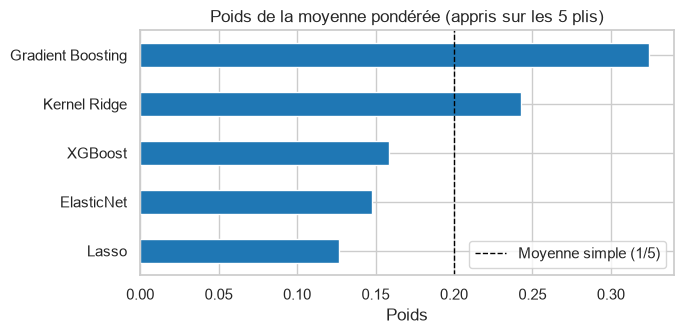

,Lasso,ElasticNet,Kernel Ridge,Gradient Boosting,XGBoost
Poids,0.127,0.148,0.243,0.324,0.159


In [10]:
model_names = list(MODELS)


def fit_weights(predictions, target):
    """Poids positifs de somme 1 qui minimisent la RMSE de la moyenne pondérée."""
    n = predictions.shape[1]
    result = minimize(
        lambda w: rmse(target, predictions @ w), np.full(n, 1 / n), method="SLSQP",
        bounds=[(0, 1)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
    )
    return result.x


P = oof_frame[model_names].to_numpy()
y = y_train.to_numpy()

# Évaluation honnête : poids appris sur 4 plis, évalués sur le 5e.
# Les poids sont appris sur les ventes typiques, comme le critère de sélection.
weighted_oof = np.empty(len(y))
for k in range(N_FOLDS):
    inside = (fold_id != k) & typical
    weighted_oof[fold_id == k] = P[fold_id == k] @ fit_weights(P[inside], y[inside])

weights = pd.Series(fit_weights(P[typical], y[typical]), index=model_names)
ensemble_oof = {"Moyenne simple": P.mean(axis=1), "Moyenne pondérée": weighted_oof}
for name, prediction in ensemble_oof.items():
    scores = fold_scores(prediction)
    cv_summary.loc[name, ["RMSE log (moyenne des plis)", "Écart type entre plis",
                          "RMSE log, toutes les ventes"]] = [
        scores.mean(), scores.std(), fold_scores(prediction, keep_all).mean()]

cv_summary = cv_summary.sort_values("RMSE log (moyenne des plis)")
display(cv_summary[["RMSE log (moyenne des plis)", "Écart type entre plis",
                    "RMSE log, toutes les ventes"]].round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
weights.sort_values().plot.barh(ax=ax, color="tab:blue")
ax.axvline(1 / len(model_names), color="black", linestyle="--", linewidth=1,
           label="Moyenne simple (1/5)")
ax.set(xlabel="Poids", title="Poids de la moyenne pondérée (appris sur les 5 plis)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(weights.round(3).rename("Poids").to_frame().T)

**Interprétation.** Les deux ensembles font mieux que chacun de leurs membres : **0,1067** pour la moyenne simple et 0,1068 pour la moyenne pondérée, contre 0,1104 pour le meilleur modèle seul (Kernel Ridge), soit un gain de 3,4 %. Le gain est régulier : l'écart type entre plis reste de l'ordre de 0,01.

Les poids appris répartissent la masse presque également entre les deux familles : 0,52 pour les modèles linéaires (Kernel Ridge 0,24, ElasticNet 0,15, Lasso 0,13) et 0,48 pour les arbres (Gradient Boosting 0,32, XGBoost 0,16). Chaque modèle garde un poids non nul. La moyenne simple, qui donne 0,6 aux modèles linéaires, est déjà proche de cet équilibre; apprendre les poids n'apporte rien en validation croisée honnête (0,1068 contre 0,1067). Avec seulement 5 poids et 1 166 maisons, l'apprentissage des poids ajoute surtout du bruit.

**Conséquence.** Le modèle retenu, selon la règle fixée d'avance, est la **moyenne simple** des cinq modèles. C'est aussi le choix le plus robuste : aucun paramètre supplémentaire.

### 5.3 Choix de prétraitement : expérience ou étape 4?

Le [notebook de prétraitement](../04_pretraitement.ipynb) (étape 4) a fait quatre choix différents de ceux de cette expérience :

| Choix | Cette expérience | Étape 4 |
|---|---|---|
| `MoSold`, `YrSold` | Catégories | Numériques |
| Logarithme | Asymétrie > 0,75, toutes les colonnes positives | Asymétrie > 0,5, sauf colonnes à 50 % de zéros ou plus, années, scores et échelles ordinales |
| Mise à l'échelle | `RobustScaler` | `StandardScaler` |
| Modalités rares | Moins de 5 maisons | Moins de 10 maisons |

Nous partons de la recette de l'expérience et remplaçons **un seul choix à la fois** par celui de l'étape 4, puis les quatre ensemble. Pour chaque variante, les cinq modèles sont réentraînés sur les mêmes plis (sans les ventes atypiques), et nous mesurons la RMSE hors pli sur les ventes typiques de chaque modèle et de leur moyenne simple. Les modèles gardent leurs hyperparamètres : ceux de Kernel Ridge ont été choisis pour des données mises à l'échelle par `RobustScaler`.

In [11]:
VARIANTS = {
    "Dates numériques": {"dates_as_category": False},
    "Log de l'étape 4": {"skew_rule": "etape4"},
    "StandardScaler": {"scaler": "standard"},
    "Rares < 10 maisons": {"min_count": 10},
    "Les quatre choix de l'étape 4": {"dates_as_category": False, "skew_rule": "etape4",
                                      "scaler": "standard", "min_count": 10},
}


def variant_scores(options):
    """RMSE hors pli (ventes typiques) des cinq modèles et de leur moyenne pour une variante."""
    options = dict(options)
    X = prepare_features(train_part, options.pop("dates_as_category", True))
    categorical = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    numeric = [c for c in X.columns if c not in categorical]
    predictions = {name: out_of_fold(name, atypical, X=X, numeric=numeric,
                                     categorical=categorical, **options)
                   for name in model_names}
    scores = {name: fold_scores(prediction).mean() for name, prediction in predictions.items()}
    scores["Moyenne simple"] = fold_scores(np.mean(list(predictions.values()), axis=0)).mean()
    return scores


if RUN_PREPROCESSING_COMPARISON:
    baseline = {name: cv_summary.loc[name, "RMSE log (moyenne des plis)"]
                for name in [*model_names, "Moyenne simple"]}
    variant_rows = {"Recette de l'expérience": baseline}
    for label, options in VARIANTS.items():
        start = time.perf_counter()
        variant_rows[label] = variant_scores(options)
        print(f"{label:<32} {time.perf_counter() - start:5.0f} s")

    variant_table = pd.DataFrame(variant_rows).T
    variant_table["Écart de la moyenne"] = (variant_table["Moyenne simple"]
                                            - baseline["Moyenne simple"])
    display(variant_table.style.format("{:.4f}").format("{:+.4f}", subset=["Écart de la moyenne"])
            .background_gradient(cmap="RdYlGn_r", subset=["Écart de la moyenne"],
                                 vmin=-0.003, vmax=0.003))

Dates numériques                    68 s
Log de l'étape 4                    62 s
StandardScaler                      94 s
Rares < 10 maisons                  64 s
Les quatre choix de l'étape 4       60 s


,Lasso,ElasticNet,Kernel Ridge,Gradient Boosting,XGBoost,Moyenne simple,Écart de la moyenne
Recette de l'expérience,0.1117,0.1112,0.1104,0.1122,0.1136,0.1067,+0.0000
Dates numériques,0.1118,0.1113,0.1098,0.1101,0.1127,0.1060,-0.0007
Log de l'étape 4,0.1102,0.1103,0.1725,0.1122,0.1136,0.1091,+0.0024
StandardScaler,0.1122,0.1117,0.1089,0.1121,0.1136,0.1066,-0.0001
Rares < 10 maisons,0.1111,0.1105,0.1099,0.1109,0.1126,0.1058,-0.0009
Les quatre choix de l'étape 4,0.1094,0.1094,0.1072,0.1106,0.1121,0.1048,-0.0019


**Interprétation.** Pris un par un, trois choix de l'étape 4 améliorent légèrement la moyenne des cinq modèles, et un la dégrade :

- **Dates numériques** (−0,0007) : le gain vient surtout des arbres (Gradient Boosting 0,1122 → 0,1101). En catégories, `YrSold` et `MoSold` deviennent 17 colonnes binaires que les arbres découpent mal; en nombre, une seule division suffit (« vendue avant ou après 2008 »).
- **Modalités rares regroupées sous 10 maisons** (−0,0009) : les cinq modèles s'améliorent un peu. Une modalité de 5 à 9 maisons apporte plus de bruit que d'information.
- **`StandardScaler`** (−0,0001) : aucun effet sur la moyenne. Kernel Ridge gagne un peu (0,1104 → 0,1089), Lasso et ElasticNet perdent un peu.
- **Log de l'étape 4, seul** (+0,0024) : Lasso et ElasticNet s'améliorent (0,1117 → 0,1102), mais **Kernel Ridge s'effondre** (0,1725). La règle de l'étape 4 ne passe plus au log les colonnes surtout nulles. Pour les colonnes qui comptent au moins 75 % de zéros (`MiscVal`, `PoolArea`, `BsmtFinSF2`…), le premier et le troisième quartile valent 0 : `RobustScaler` ne peut pas les mettre à l'échelle et les laisse brutes, jusqu'à 15 500 pour `MiscVal`. Le noyau polynomial, qui dépend des produits entre colonnes, est alors dominé par ces quelques valeurs. Avec `StandardScaler`, la plus grande valeur tombe à 28.

Les arbres donnent exactement le même score avec les deux règles de log et les deux mises à l'échelle (0,1122 et 0,1136) : ces transformations conservent l'ordre des valeurs, la seule chose qu'utilise un arbre.

**Les quatre choix ensemble** donnent la meilleure moyenne : **0,1048**, contre 0,1067 (−0,0019). Les cinq modèles s'améliorent, Kernel Ridge le plus (0,1104 → 0,1072). Le log de l'étape 4 et `StandardScaler` vont donc ensemble : chacun est neutre ou nuisible seul, mais la combinaison est la meilleure.

**Prudence.** Les écarts (0,001 à 0,002) sont plus petits que l'écart type entre plis (environ 0,01). Ils sont cependant mesurés sur les mêmes plis et vont dans le même sens pour les cinq modèles, ce qui les rend plus crédibles qu'un écart isolé.

**Conséquence.** Les choix de l'étape 4 sont confirmés pour cet ensemble, à condition de les adopter ensemble. Les sections suivantes gardent la recette de l'expérience pour que les résultats de validation restent comparables avec la version précédente de ce notebook.

## 6. Entraînement final et évaluation sur la validation

Les cinq modèles sont réentraînés sur les 1 168 maisons d'entraînement (sans les deux ventes atypiques), puis évalués **une seule fois** sur les 292 maisons de validation. Le **modèle retenu** est celui qui a la meilleure RMSE en validation croisée à la section 5, choisi **avant** de regarder la validation.

In [12]:
def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "RMSE log": np.sqrt(np.mean((np.log(y_pred) - np.log(y_true)) ** 2)),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }


def combine(log_predictions, method):
    """Combiner un DataFrame de prédictions log (une colonne par modèle)."""
    if method == "Moyenne simple":
        return log_predictions[model_names].mean(axis=1)
    if method == "Moyenne pondérée":
        return log_predictions[model_names] @ weights
    return log_predictions[method]


fit_mask = ~atypical
valid_log = pd.DataFrame(index=valid_part.index)
for name in model_names:
    model = make_model(name).fit(X_train[fit_mask], y_train[fit_mask])
    valid_log[name] = model.predict(X_valid)
for method in ensemble_oof:
    valid_log[method] = combine(valid_log, method)

final_name = cv_summary.index[0]
print(f"Modèle retenu (meilleure validation croisée) : {final_name}")

results = pd.DataFrame({
    method: regression_metrics(valid_part["SalePrice"], np.exp(valid_log[method]))
    for method in valid_log
}).T.sort_values("RMSE log")
results.insert(0, "RMSE log (validation croisée)", cv_summary["RMSE log (moyenne des plis)"])
display(results.style.format({
    "RMSE log (validation croisée)": "{:.4f}", "RMSE log": "{:.4f}", "RMSE ($)": "{:,.0f}",
    "MAE ($)": "{:,.0f}", "R²": "{:.3f}",
}))

Modèle retenu (meilleure validation croisée) : Moyenne simple


,RMSE log (validation croisée),RMSE log,RMSE ($),MAE ($),R²
Moyenne simple,0.1067,0.1233,"22,734","13,682",0.933
Moyenne pondérée,0.1068,0.1238,"22,566","13,600",0.934
Kernel Ridge,0.1104,0.1247,"22,920","14,646",0.932
XGBoost,0.1136,0.1257,"23,937","14,058",0.925
Lasso,0.1117,0.1264,"23,950","14,893",0.925
ElasticNet,0.1112,0.1276,"24,200","15,001",0.924
Gradient Boosting,0.1122,0.1322,"23,273","14,131",0.929


**Interprétation.** Sur les 292 maisons de validation, l'ordre de la validation croisée est en grande partie respecté. La **moyenne simple** obtient la meilleure RMSE log, **0,1233**, devant la moyenne pondérée (0,1238) et le meilleur modèle seul, Kernel Ridge (0,1247). Elle a aussi la meilleure MAE (13 682 \$). Le gain de l'ensemble est plus petit qu'en validation croisée (−0,0014 contre −0,0037 par rapport au meilleur modèle) : avec 292 maisons, un écart de cet ordre reste dans la marge d'incertitude.

Gradient Boosting, le modèle le plus lourd de la moyenne pondérée, est le **moins bon** modèle seul en validation (0,1322), alors qu'il était au milieu du classement en validation croisée. Choisir un seul modèle d'après la validation croisée aurait donc pu mal tourner; l'ensemble protège contre ce risque.

Comme dans l'expérience 03, les erreurs de validation sont plus élevées que celles de la validation croisée (0,123 contre 0,107) : ces 292 maisons sont plus difficiles que la moyenne. Par rapport au modèle retenu de l'expérience 03 (0,1296, sur 291 de ces maisons), l'erreur baisse de 5 % (**0,1233**), et fait mieux que la meilleure configuration XGBoost de l'expérience 03 (0,1253, calculée sur 291 maisons communes).

### Prédictions et prix réels

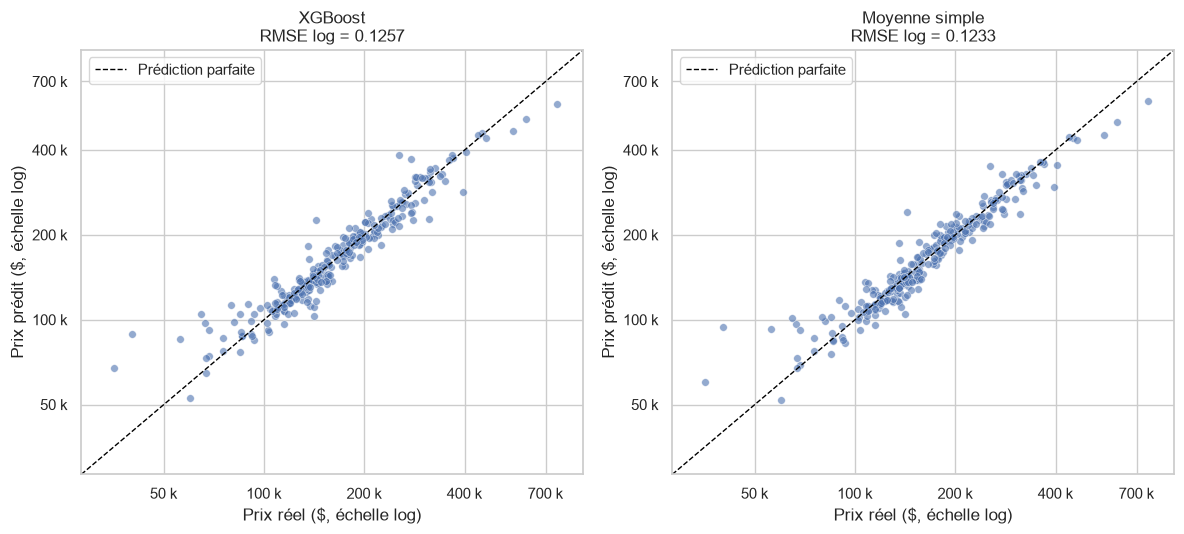

Erreur log moyenne par quartile de prix réel (positif = surestimation) :


SalePrice,1er quartile,2e quartile,3e quartile,4e quartile
XGBoost,0.059,-0.010,-0.001,-0.026
Lasso,0.044,-0.021,0.021,-0.034
Moyenne simple,0.054,-0.015,0.012,-0.032


In [13]:
real = valid_part["SalePrice"]
panels = ["XGBoost", final_name]
ticks = [50_000, 100_000, 200_000, 400_000, 700_000]
tick_labels = [f"{tick // 1000} k" for tick in ticks]
limits = (real.min() * 0.8, real.max() * 1.2)

fig, axes = plt.subplots(1, len(panels), figsize=(12, 5.5))
for ax, method in zip(axes, panels):
    predicted = np.exp(valid_log[method])
    sns.scatterplot(x=real, y=predicted, alpha=0.6, s=30, ax=ax)
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=1,
            label="Prédiction parfaite")
    ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits,
           xlabel="Prix réel ($, échelle log)", ylabel="Prix prédit ($, échelle log)")
    ax.set_xticks(ticks, tick_labels)
    ax.set_yticks(ticks, tick_labels)
    ax.minorticks_off()
    ax.set_title(f"{method}\nRMSE log = {results.loc[method, 'RMSE log']:.4f}")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Erreur par tranche de prix : l'ensemble corrige-t-il la compression des arbres?
bands = pd.qcut(real, 4, labels=["1er quartile", "2e quartile", "3e quartile", "4e quartile"])
by_band = pd.DataFrame({
    method: (valid_log[method] - np.log(real)).groupby(bands, observed=True).mean()
    for method in ["XGBoost", "Lasso", final_name]
})
print("Erreur log moyenne par quartile de prix réel (positif = surestimation) :")
display(by_band.T.round(3))

**Question.** L'ensemble corrige-t-il la compression des prédictions aux extrémités, observée pour XGBoost dans l'expérience 03?

**Observation.** Peu. Les deux nuages sont très semblables. Dans le quartile des maisons les moins chères, l'erreur log moyenne est de +0,059 pour XGBoost (surestimation d'environ 6 %), +0,044 pour le Lasso et +0,054 pour l'ensemble. Dans le quartile le plus cher, les trois sous-estiment d'environ 3 % (−0,026 à −0,034). Les modèles linéaires réduisent un peu la surestimation du bas du marché mais ne la suppriment pas.

**Interprétation.** La compression ne vient pas seulement des arbres : les maisons très bon marché de la validation (zonage commercial, ventes particulières) ont des prix que les variables disponibles expliquent mal, quel que soit le modèle. L'ensemble réduit surtout les erreurs **au milieu** de la distribution, là où les deux familles se trompent sur des maisons différentes.

## 7. Soumission Kaggle

Les cinq modèles sont réentraînés avec les mêmes hyperparamètres sur **les 1 460 maisons de `train.csv`**, sans les deux ventes atypiques, puis combinés selon la méthode retenue (avec les poids appris à la section 5 pour la moyenne pondérée). Le fichier est écrit dans `submissions/`, ignoré par Git, dans l'ordre de `sample_submission.csv`.

In [14]:
if MAKE_SUBMISSION:
    X_full = prepare_features(train_full)
    y_full = np.log(train_full["SalePrice"])
    keep_full = ~atypical_mask(train_full)

    test_log = pd.DataFrame(index=test.index)
    for name in model_names:
        model = make_model(name).fit(X_full[keep_full], y_full[keep_full])
        test_log[name] = model.predict(X_test)

    sample = pd.read_csv(data_dir / "sample_submission.csv")
    submission = pd.DataFrame({"Id": test["Id"],
                               "SalePrice": np.exp(combine(test_log, final_name))})
    submission = sample[["Id"]].merge(submission, on="Id", how="left")
    assert len(submission) == len(test) and submission["SalePrice"].notna().all()

    submission_path.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(submission_path, index=False)
    print(f"Soumission écrite : {submission_path.relative_to(root)} "
          f"({final_name}, entraînement sur {keep_full.sum()} ventes)")
    print(f"Prix médian prédit : {format_dollars(submission['SalePrice'].median())}")

Soumission écrite : submissions\04_ensemble.csv (Moyenne simple, entraînement sur 1458 ventes)
Prix médian prédit : 156 751 $


## 8. Limites et pistes

- **Critère d'évaluation.** Exclure les deux ventes atypiques de l'évaluation est un choix : il suppose que les maisons à prédire ressemblent aux ventes typiques. Or `test.csv` contient une maison au profil identique (Id 2550 : 5 095 pi², quartier `Edwards`, qualité 10, vente `Partial`). Si son prix réel est aussi bas que celui des maisons 524 et 1299, les modèles linéaires la surestimeront fortement et pèseront sur le score Kaggle.
- **Hyperparamètres peu réglés.** Kernel Ridge et Gradient Boosting utilisent des valeurs usuelles, sans recherche. Une recherche par validation croisée (comme dans l'expérience 03) pourrait améliorer chacun d'eux, mais l'expérience 03 suggère des gains de l'ordre du millième.
- **Deux modèles presque identiques.** Lasso et ElasticNet ont des erreurs corrélées à 1,00 : la moyenne simple donne en pratique un poids double à cette approche. Les remplacer par un seul modèle linéaire, ou ajouter un modèle d'une autre famille (LightGBM, CatBoost, forêt aléatoire), rendrait l'ensemble plus diversifié.
- **Empilement (*stacking*).** Un méta-modèle (par exemple une régression Ridge) entraîné sur les prédictions hors pli pourrait apprendre des combinaisons plus fines que des poids fixes. Le résultat de la moyenne pondérée, qui n'apporte rien, suggère que le gain serait faible.
- **`log1p` au lieu de Box-Cox.** Plusieurs variables restent très asymétriques après `log1p` (`PoolArea`, `MiscVal`, `LowQualFinSF`) : elles sont surtout nulles, avec quelques valeurs positives. Aucune transformation ne corrige cette forme; un indicateur de présence (comme `HasPool`) porte l'essentiel de leur information.
- **Une seule partition de validation.** Avec 292 maisons, les écarts de quelques millièmes entre l'ensemble et Kernel Ridge ne sont pas significatifs. La validation croisée, plus stable, confirme cependant l'avantage de l'ensemble.